In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import arviz as az
from matplotlib.patches import Patch

jax.config.update('jax_platforms', 'cpu')
numpyro.set_host_device_count(4)

plt.style.use('bmh')

In [24]:
df = pd.read_csv("bml-component-data.csv")
print(f"Loaded {len(df)} measurements across {df['index'].nunique()} components")


component_idx = df["index"].values.astype(int)
t_obs         = df["day"].values.astype(float)
y_obs         = df["integrity"].values.astype(float)

N_components = df["index"].nunique()
df_by_comp   = df.drop_duplicates("index").sort_values("index")
ID_by_comp   = df_by_comp["ID"].values
X_raw        = df_by_comp[["X1", "X2", "X3", "X4", "X5"]].values

#Standardise X
X_mean = X_raw.mean(axis=0)
X_std  = X_raw.std(axis=0)
X_norm = (X_raw - X_mean) / X_std

print(f"X_raw shape: {X_raw.shape},  X_norm shape: {X_norm.shape}")

test_indices = np.arange(50, 75)

Loaded 879 measurements across 75 components
X_raw shape: (75, 5),  X_norm shape: (75, 5)


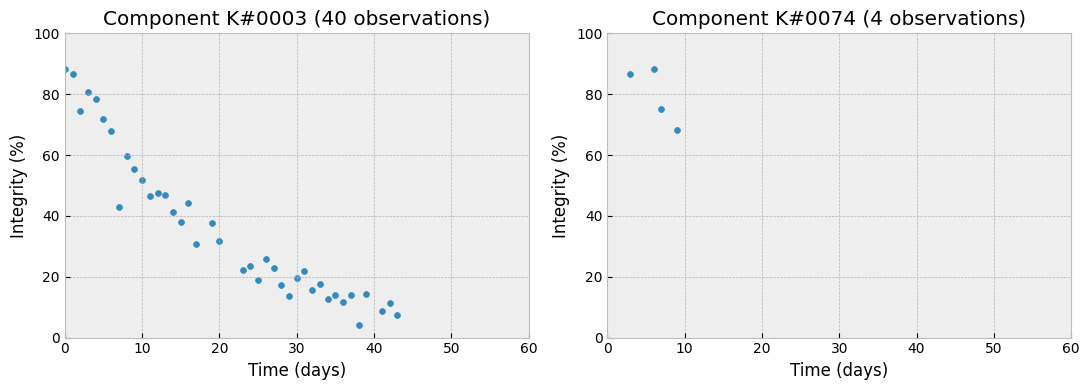

In [25]:
def plot_component_data(idx, ax):
    rows = df[df["index"] == idx]
    ax.scatter(rows["day"], rows["integrity"], s=18)
    ax.set_xlim(0, 60); ax.set_ylim(0, 100)
    ax.set_xlabel("Time (days)"); ax.set_ylabel("Integrity (%)")
    ax.set_title(f"Component {rows['ID'].iloc[0]} ({len(rows)} observations)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_component_data(3,  axes[0])
plot_component_data(74, axes[1])
plt.tight_layout()
plt.show()

In [26]:
def baseline_model(component_idx, t, y=None, n_components=N_components):
    #Priors
    mu_u    = numpyro.sample("mu_u",    dist.Normal(90.0, 10.0))
    sigma_u = numpyro.sample("sigma_u", dist.HalfNormal(10.0))
    mu_v    = numpyro.sample("mu_v",    dist.Normal(5.0, 4.0))
    sigma_v = numpyro.sample("sigma_v", dist.HalfNormal(3.0))

    with numpyro.plate("component", n_components):
        u_raw = numpyro.sample("u_raw", dist.Normal(0.0, 1.0))
        v_raw = numpyro.sample("v_raw", dist.Normal(0.0, 1.0))
    u = numpyro.deterministic("u", mu_u + u_raw * sigma_u)
    v = numpyro.deterministic("v", mu_v + v_raw * sigma_v)

    f = u[component_idx] * jnp.exp(-v[component_idx] * t / 100.0)

    sigma_y = numpyro.sample("sigma_y", dist.HalfNormal(7.5))

    with numpyro.plate("data", len(t)):
        numpyro.sample("obs", dist.Normal(f, sigma_y), obs=y)

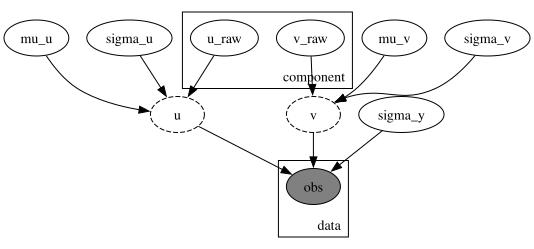

In [27]:
numpyro.render_model(
        baseline_model,
        model_args=(component_idx, t_obs, y_obs),
        render_params=True )

In [28]:
num_samples =  2000
num_warmup = 2000
seed = 0

nuts_kernel = NUTS(baseline_model)
mcmc_baseline = MCMC(nuts_kernel, num_samples=num_samples, num_warmup=num_warmup, num_chains=4)
rng_key = jax.random.PRNGKey(seed)
mcmc_baseline.run(rng_key, component_idx, t_obs, y_obs)
mcmc_baseline.print_summary()

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_u     89.72      0.87     89.73     88.30     91.14   5939.01      1.00
      mu_v      3.93      0.21      3.93      3.58      4.28   1239.75      1.00
   sigma_u      5.28      0.82      5.24      3.99      6.65   3816.68      1.00
   sigma_v      1.59      0.17      1.58      1.31      1.86   3118.88      1.00
   sigma_y      5.10      0.13      5.10      4.90      5.33  12829.26      1.00
  u_raw[0]      0.82      0.46      0.80      0.05      1.54  13044.14      1.00
  u_raw[1]     -0.45      0.83     -0.45     -1.85      0.84  15360.92      1.00
  u_raw[2]      1.69      0.46      1.68      0.94      2.45  10482.98      1.00
  u_raw[3]     -0.09      0.43     -0.09     -0.83      0.59  12755.91      1.00
  u_raw[4]     -0.49      0.74     -0.49     -1.74      0.72  17375.47      1.00
  u_raw[5]     -0.07      0.78     -0.07     -1.38      1.21  16727.49      1.00
  u_raw[6]      0.37      0

array([[<Axes: title={'center': 'u'}>, <Axes: title={'center': 'u'}>],
       [<Axes: title={'center': 'v'}>, <Axes: title={'center': 'v'}>],
       [<Axes: title={'center': 'mu_u'}>,
        <Axes: title={'center': 'mu_u'}>],
       [<Axes: title={'center': 'sigma_u'}>,
        <Axes: title={'center': 'sigma_u'}>],
       [<Axes: title={'center': 'mu_v'}>,
        <Axes: title={'center': 'mu_v'}>],
       [<Axes: title={'center': 'sigma_v'}>,
        <Axes: title={'center': 'sigma_v'}>],
       [<Axes: title={'center': 'sigma_y'}>,
        <Axes: title={'center': 'sigma_y'}>]], dtype=object)

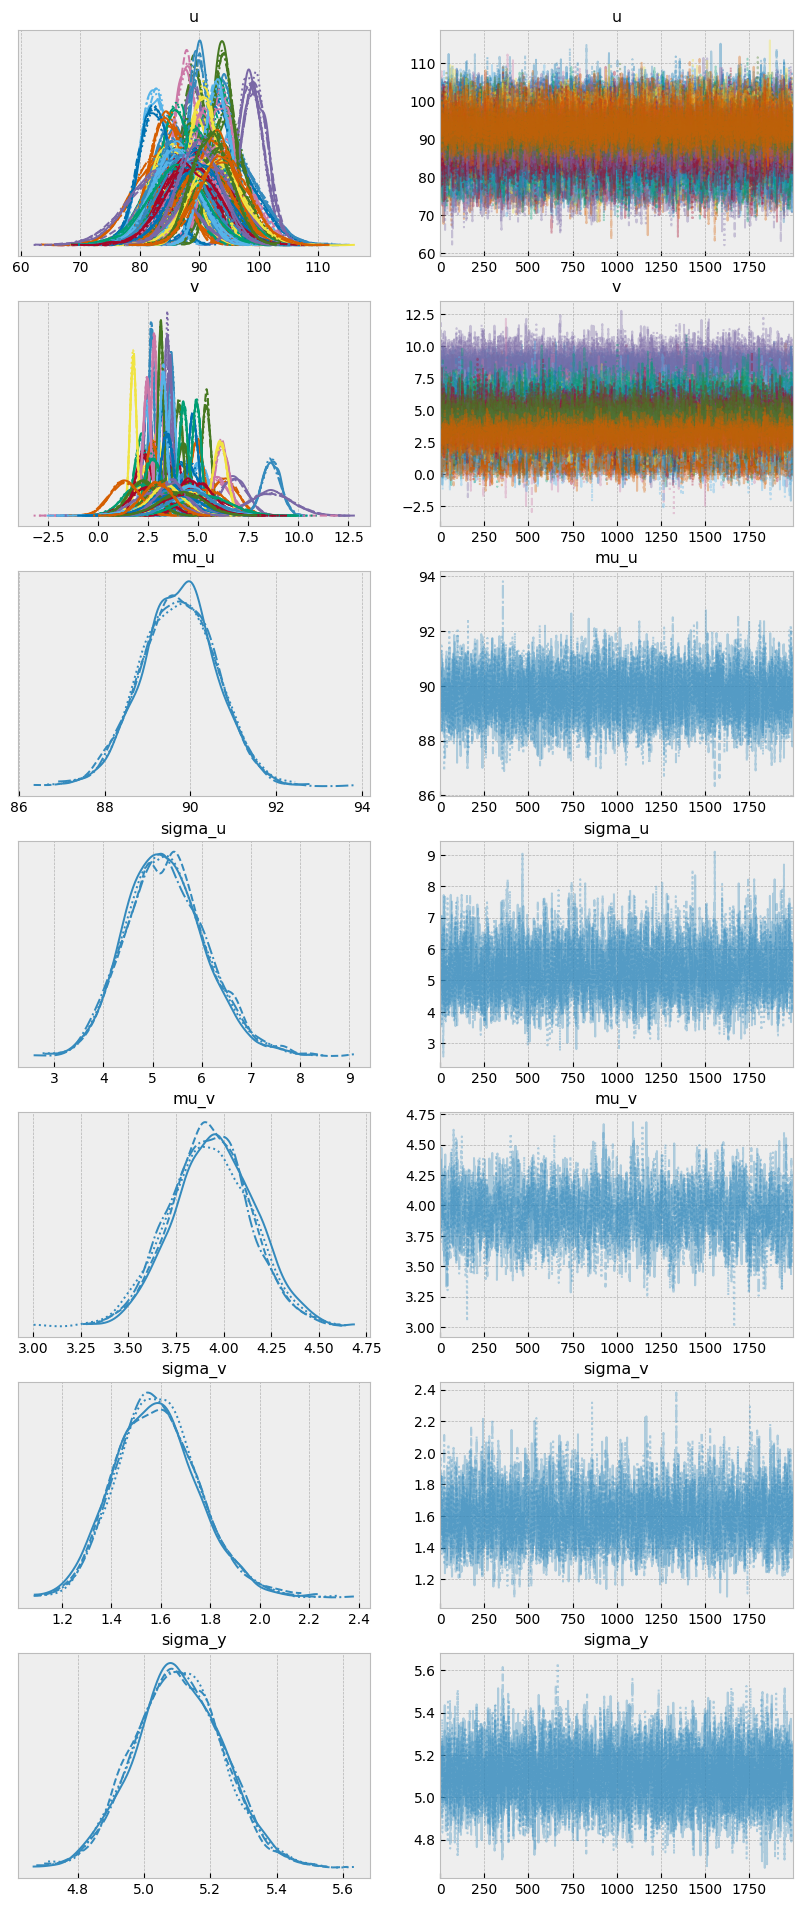

In [29]:
data_baseline = az.from_numpyro(mcmc_baseline)

trace_vars_baseline = ["u", "v", "mu_u", "sigma_u", "mu_v", "sigma_v", "sigma_y"]
az.plot_trace(data_baseline, var_names=trace_vars_baseline, compact=True,
              figsize=(10, 24))

In [30]:
def baseline_predict_function(samples, comp_idx, t_grid):
    u_s = np.asarray(samples["u"][:, comp_idx])
    v_s = np.asarray(samples["v"][:, comp_idx])
    return u_s[:, None] * np.exp(-v_s[:, None] * t_grid[None, :] / 100.0)


def plot_fit(predict_function_fn, samples, comp_idx, ax, t_max=60):
    t_grid = np.linspace(0, t_max, 200)
    F = predict_function_fn(samples, comp_idx, t_grid)
    f_mean = F.mean(axis=0)
    f_std  = F.std(axis=0)
    noise_var = np.mean(np.asarray(samples["sigma_y"]) ** 2)
    f_std_full = np.sqrt(f_std ** 2 + noise_var)

    rows = df[df["index"] == comp_idx]

    ax.fill_between(t_grid, f_mean - 1.96 * f_std_full, f_mean + 1.96 * f_std_full,
                    color="Goldenrod", alpha=0.20,
                    label=r"$\pm 1.96\,\sigma$ (function + noise)")

    ax.fill_between(t_grid, f_mean - 1.96 * f_std, f_mean + 1.96 * f_std,
                    color="Goldenrod", alpha=0.5,
                    label=r"$\pm 1.96\,\sigma$ (function)")
    ax.plot(t_grid, f_mean, color="Firebrick", lw=2, label="posterior mean")
    ax.scatter(rows["day"], rows["integrity"], s=22, color="Steelblue",
               zorder=4, label="observations")
    ax.set_xlim(0, t_max)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Integrity (%)")
    ax.set_title(f"Component {ID_by_comp[comp_idx]} ({len(rows)} obs.)")
    ax.legend()

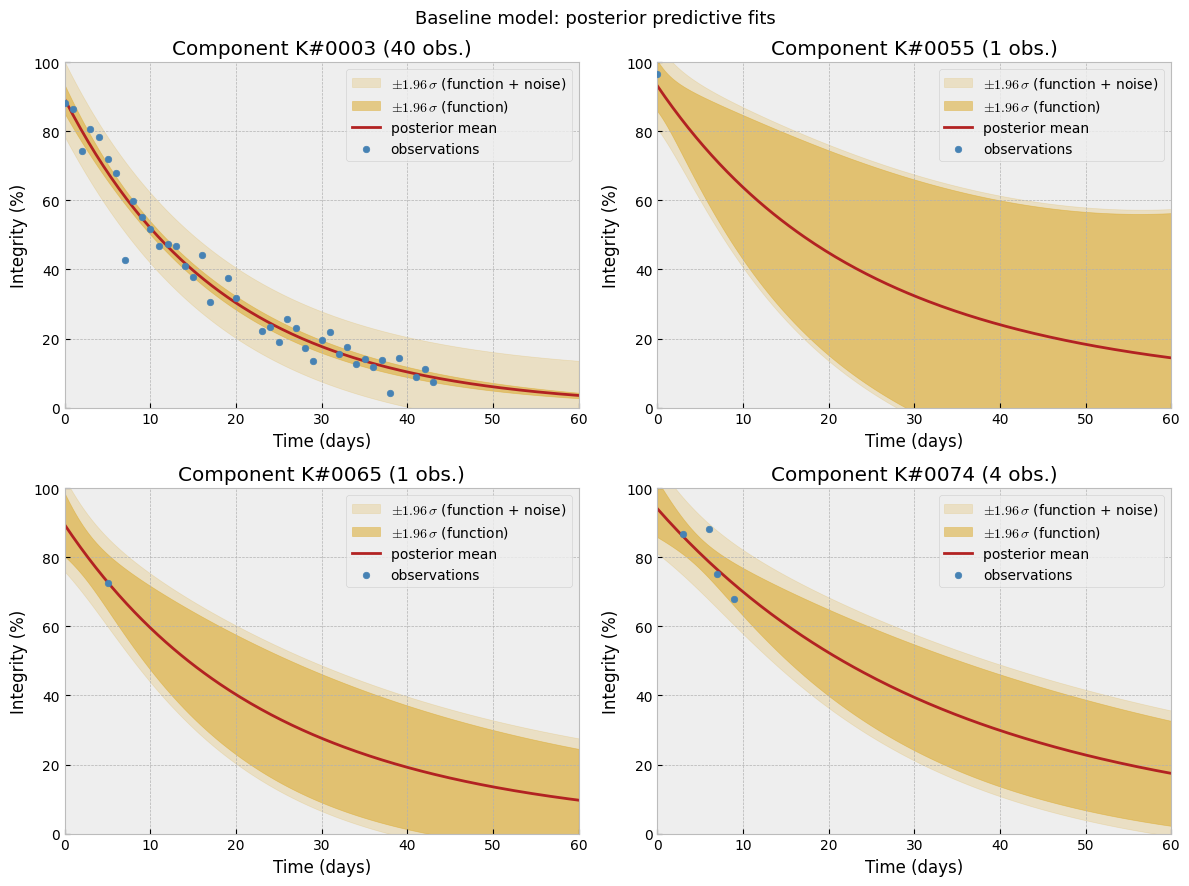

In [31]:
samples_baseline = mcmc_baseline.get_samples()

#One with lots of data and three with not much data
plot_components = [3, 55, 65, 74]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for k, idx in enumerate(plot_components):
    plot_fit(baseline_predict_function, samples_baseline, idx, axes.ravel()[k])
fig.suptitle("Baseline model: posterior predictive fits", fontsize=13)
plt.tight_layout()
plt.show()

In [32]:
def enhanced_model(component_idx, t, X, y=None, n_components=N_components):
    mu_u    = numpyro.sample("mu_u",    dist.Normal(90.0, 10.0))
    sigma_u = numpyro.sample("sigma_u", dist.HalfNormal(10.0))
    mu_v    = numpyro.sample("mu_v",    dist.Normal(4.0, 4.0)) #5,4
    sigma_v = numpyro.sample("sigma_v", dist.HalfNormal(3.0))

    sigma_w = numpyro.sample("sigma_w", dist.HalfNormal(1.0))

    with numpyro.plate("component", n_components):
        u_raw = numpyro.sample("u_raw", dist.Normal(0.0, 1.0))
        v_raw = numpyro.sample("v_raw", dist.Normal(0.0, 1.0))
    u = numpyro.deterministic("u", mu_u + u_raw * sigma_u)
    v = numpyro.deterministic("v", mu_v + v_raw * sigma_v)


    with numpyro.plate("weight", 5):
        w = numpyro.sample("w", dist.Normal(0.0, sigma_w))

    sigma_y = numpyro.sample("sigma_y", dist.HalfNormal(7.5))

    decay_rate = v + X @ w

    f = u[component_idx] * jnp.exp(-decay_rate[component_idx] * t / 100.0)

    with numpyro.plate("data", len(t)):
        numpyro.sample("obs", dist.Normal(f, sigma_y), obs=y)

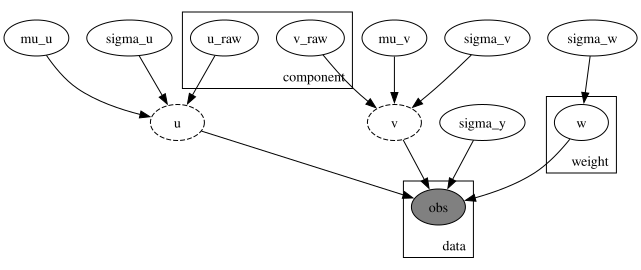

In [33]:
numpyro.render_model(enhanced_model, model_args=(component_idx, t_obs, jnp.asarray(X_norm), y_obs),render_params=True)



In [34]:
nuts_kernel = NUTS(enhanced_model)
mcmc_enhanced = MCMC(nuts_kernel, num_samples=num_samples, num_warmup=num_warmup, num_chains=4)
mcmc_enhanced.run(rng_key,
                  component_idx, t_obs, jnp.asarray(X_norm), y_obs) #X_norm
mcmc_enhanced.print_summary()

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_u     90.33      0.77     90.32     89.05     91.56   5651.35      1.00
      mu_v      4.17      0.08      4.17      4.03      4.30   6050.83      1.00
   sigma_u      4.78      0.62      4.75      3.72      5.77   3852.65      1.00
   sigma_v      0.35      0.07      0.34      0.24      0.45   3810.26      1.00
   sigma_w      0.89      0.29      0.83      0.47      1.31  11159.16      1.00
   sigma_y      5.09      0.13      5.08      4.88      5.29  12314.44      1.00
  u_raw[0]      0.82      0.49      0.81      0.02      1.62  13235.62      1.00
  u_raw[1]      0.26      0.78      0.26     -1.00      1.57  13430.93      1.00
  u_raw[2]      1.71      0.47      1.70      0.96      2.50  10860.61      1.00
  u_raw[3]     -0.21      0.45     -0.20     -0.95      0.54  15369.59      1.00
  u_raw[4]     -0.14      0.67     -0.14     -1.29      0.91  14218.85      1.00
  u_raw[5]     -0.46      0

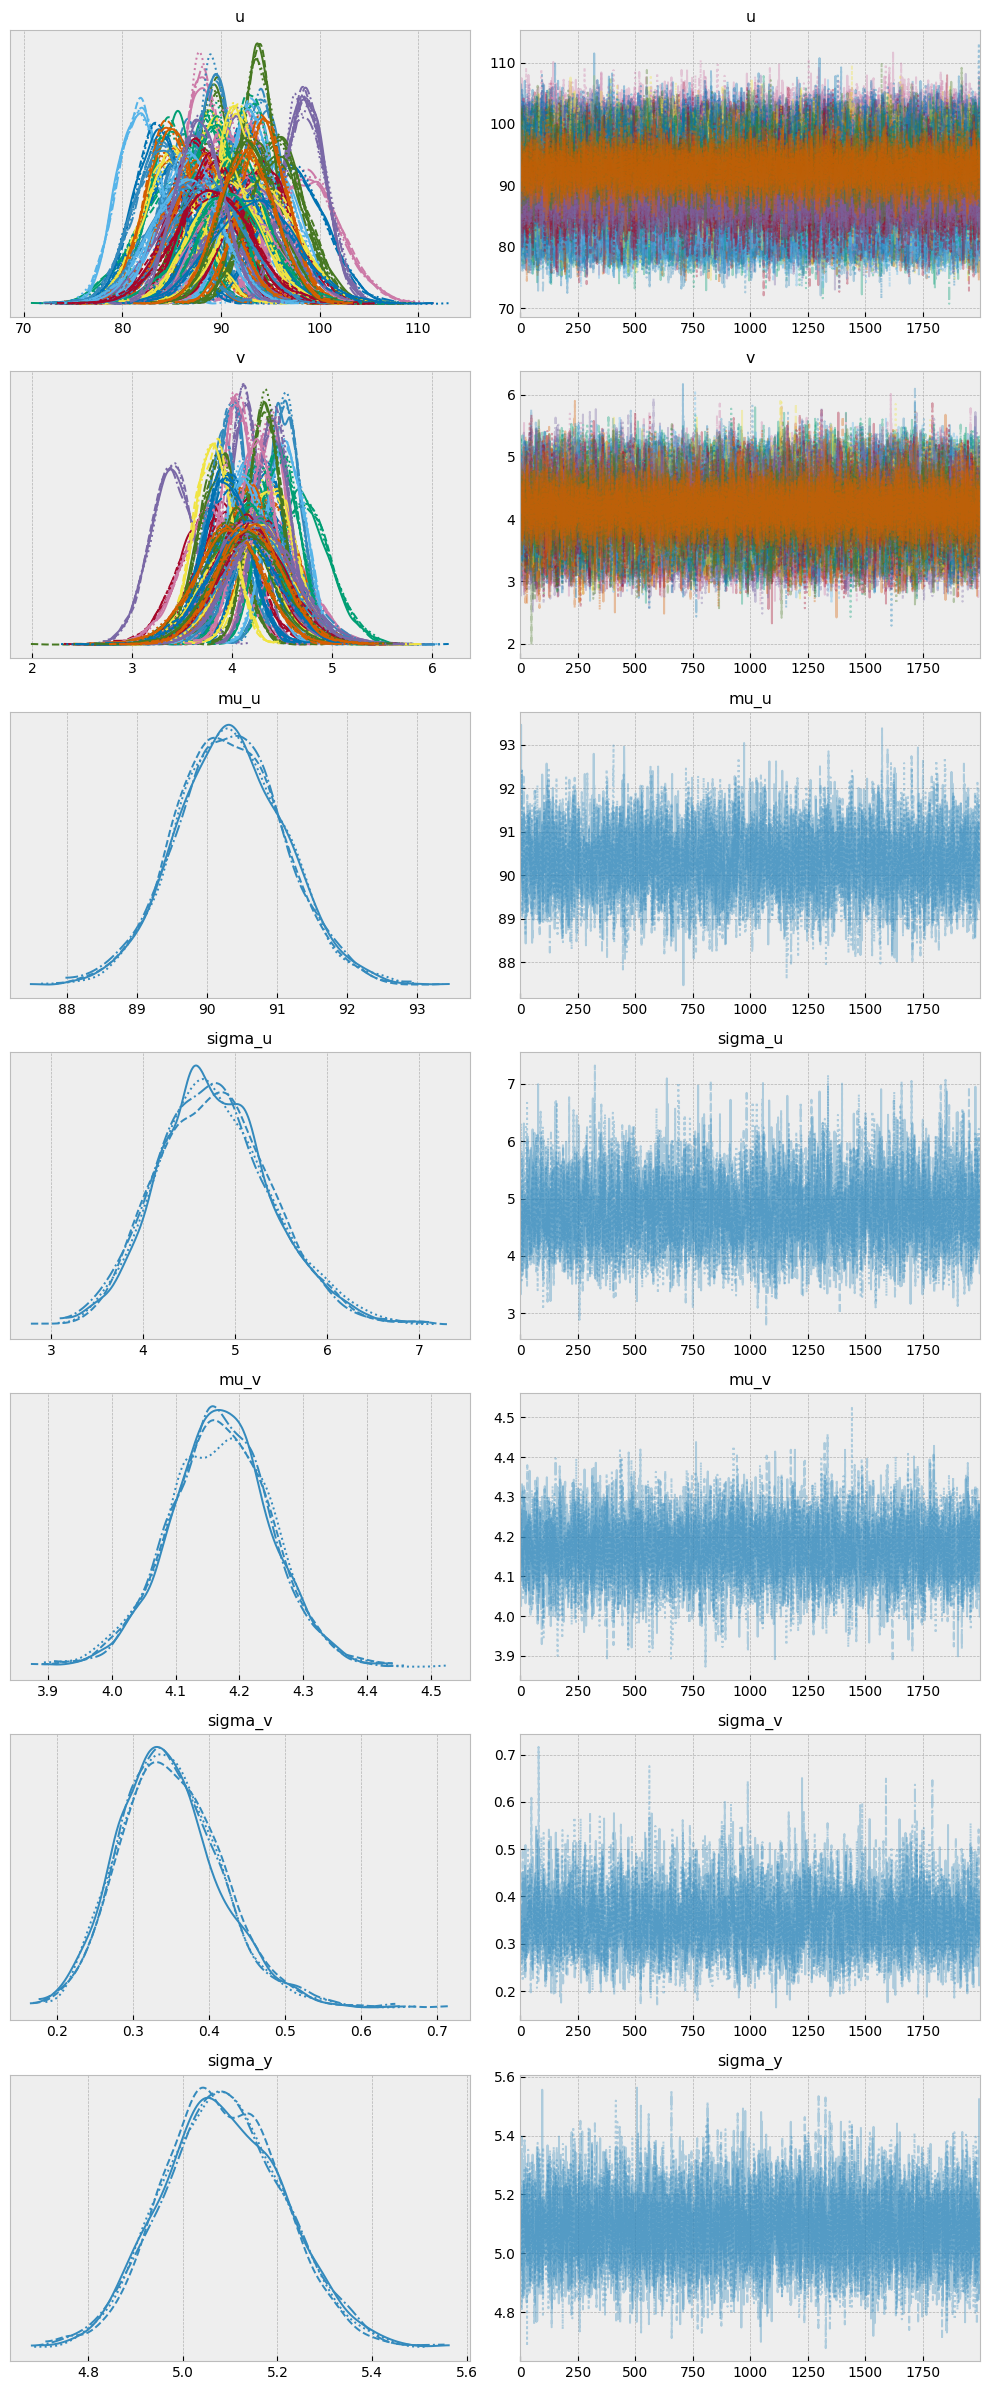

In [35]:
data_enhanced = az.from_numpyro(mcmc_enhanced)

trace_vars_enhanced = ["u", "v", "mu_u", "sigma_u", "mu_v", "sigma_v", "sigma_y"]
az.plot_trace(data_enhanced, var_names=trace_vars_enhanced, compact=True,
              figsize=(10, 24))
plt.tight_layout()
plt.show()

In [36]:
samples_enhanced = mcmc_enhanced.get_samples()

def enhanced_predict_function(samples, comp_idx, t_grid):
    u_s     = np.asarray(samples["u"][:, comp_idx])
    v_s     = np.asarray(samples["v"][:, comp_idx])
    w_s     = np.asarray(samples["w"])
    x_i     = X_norm[comp_idx]
    decay_s = v_s + w_s @ x_i
    return u_s[:, None] * np.exp(-decay_s[:, None] * t_grid[None, :] / 100.0)


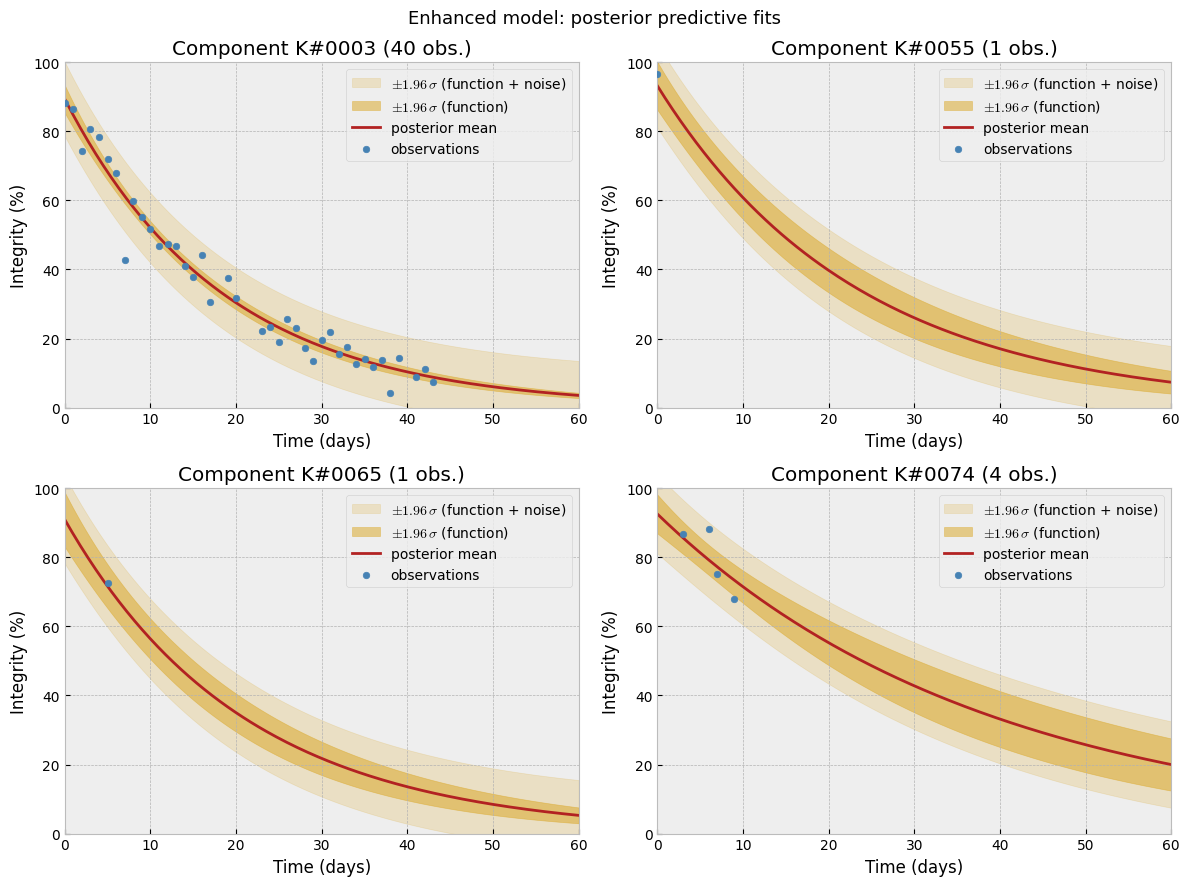

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for k, idx in enumerate(plot_components):
    plot_fit(enhanced_predict_function, samples_enhanced, idx, axes.ravel()[k])
fig.suptitle("Enhanced model: posterior predictive fits", fontsize=13)
plt.tight_layout()
plt.show()

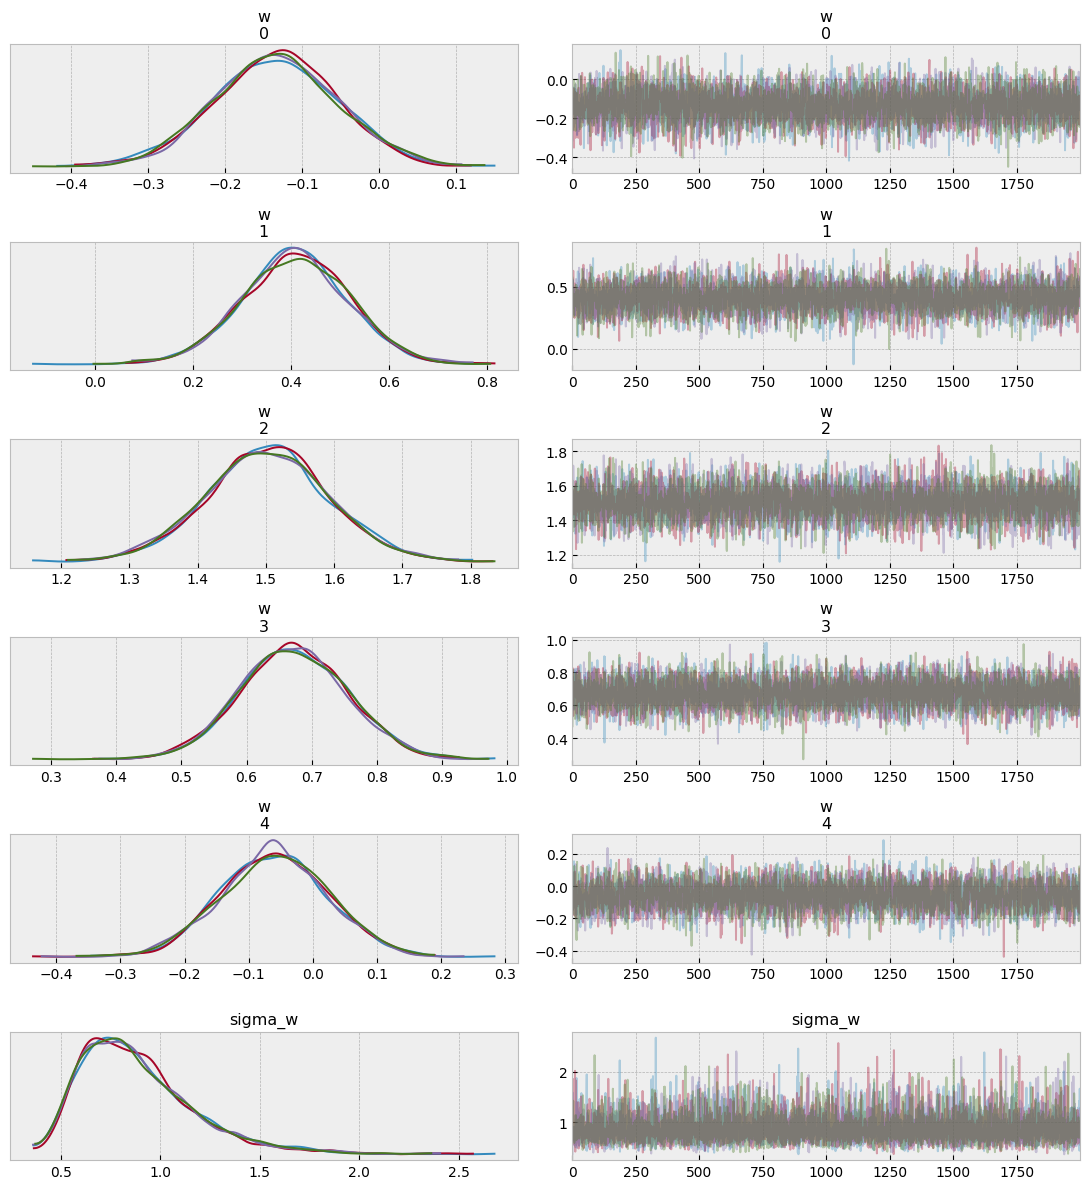

In [38]:
az.plot_trace(data_enhanced, var_names=["w", "sigma_w"], compact=False,
              figsize=(11, 12))
plt.tight_layout()
plt.show()

In [39]:
w_samples = np.asarray(samples_enhanced["w"])   # (S, 5)

w_mean    = w_samples.mean(axis=0)
w_std     = w_samples.std(axis=0)
w_q025    = np.quantile(w_samples, 0.025, axis=0)
w_q975    = np.quantile(w_samples, 0.975, axis=0)
prob_w  = (w_samples > 0).mean(axis=0)

w_orig    = w_mean / X_std
w_orig_lo = w_q025 / X_std
w_orig_hi = w_q975 / X_std

w_summary = pd.DataFrame({
    "weight":            [f"w_{j+1}" for j in range(5)],
    "mean (std X)":      w_mean,
    "std":               w_std,
    "2.5%":              w_q025,
    "97.5%":             w_q975,
    "P(w > 0)":          prob_w,
    "mean (original X)": w_orig,
})
print(w_summary.to_string(index=False, float_format='{:.4f}'.format))

weight  mean (std X)    std    2.5%  97.5%  P(w > 0)  mean (original X)
   w_1       -0.1344 0.0803 -0.2942 0.0229    0.0481            -0.0855
   w_2        0.4091 0.1088  0.1948 0.6204    0.9998             0.1678
   w_3        1.5026 0.0901  1.3234 1.6827    1.0000             1.0656
   w_4        0.6721 0.0818  0.5131 0.8315    1.0000             0.2252
   w_5       -0.0601 0.0829 -0.2194 0.1005    0.2356            -0.0297


In [40]:
def predict_below_threshold(samples, comp_idx, t_value=30.0, threshold=30.0,seed=42):
    u_s     = np.asarray(samples["u"][:, comp_idx])
    v_s     = np.asarray(samples["v"][:, comp_idx])
    w_s     = np.asarray(samples["w"])
    x_i     = X_norm[comp_idx]

    decay_s = v_s + w_s @ x_i
    f_s     = u_s * np.exp(-decay_s * t_value / 100.0)
    sigma_s = np.asarray(samples["sigma_y"])

    rng = np.random.default_rng(seed)
    y_s = f_s + sigma_s * rng.standard_normal(size=f_s.shape)
    return float(np.mean(y_s <= threshold))

probabilities = np.array([
    predict_below_threshold(samples_enhanced, i, t_value=30.0, threshold=30.0)
    for i in test_indices
])

predictions_df = pd.DataFrame({
    "ID":          ID_by_comp[test_indices],
    "index":       test_indices,
    "probability": probabilities,
})
print(predictions_df.to_string(index=False, float_format='{:.6f}'.format))

    ID  index  probability
K#0050     50     0.260125
K#0051     51     0.991250
K#0052     52     1.000000
K#0053     53     0.461750
K#0054     54     0.039375
K#0055     55     0.752875
K#0056     56     0.945750
K#0057     57     0.001500
K#0058     58     0.999000
K#0059     59     0.560125
K#0060     60     0.384750
K#0061     61     0.036375
K#0062     62     0.135125
K#0063     63     0.040250
K#0064     64     0.000125
K#0065     65     0.927875
K#0066     66     0.999250
K#0067     67     1.000000
K#0068     68     0.090000
K#0069     69     0.990125
K#0070     70     0.903000
K#0071     71     0.771750
K#0072     72     0.194750
K#0073     73     0.857750
K#0074     74     0.021250


In [42]:
predictions_df.to_csv("predictions.csv", index=False, float_format="%.6f")
print("Wrote predictions.csv:")
print(open("predictions.csv").read()[:500])

Wrote predictions.csv:
ID,index,probability
K#0050,50,0.260125
K#0051,51,0.991250
K#0052,52,1.000000
K#0053,53,0.461750
K#0054,54,0.039375
K#0055,55,0.752875
K#0056,56,0.945750
K#0057,57,0.001500
K#0058,58,0.999000
K#0059,59,0.560125
K#0060,60,0.384750
K#0061,61,0.036375
K#0062,62,0.135125
K#0063,63,0.040250
K#0064,64,0.000125
K#0065,65,0.927875
K#0066,66,0.999250
K#0067,67,1.000000
K#0068,68,0.090000
K#0069,69,0.990125
K#0070,70,0.903000
K#0071,71,0.771750
K#0072,72,0.194750
K#0073,73,0.857750
K#0074,74,0.021250



In [43]:
np.savez_compressed(
    "deployable_model.npz",
    u_samples       = np.asarray(samples_enhanced["u"]),
    v_samples       = np.asarray(samples_enhanced["v"]),
    w_samples       = np.asarray(samples_enhanced["w"]),
    sigma_y_samples = np.asarray(samples_enhanced["sigma_y"]),
    X_mean          = X_mean,
    X_std           = X_std,
    X_raw           = X_raw,
    component_ids   = ID_by_comp.astype(object),
)

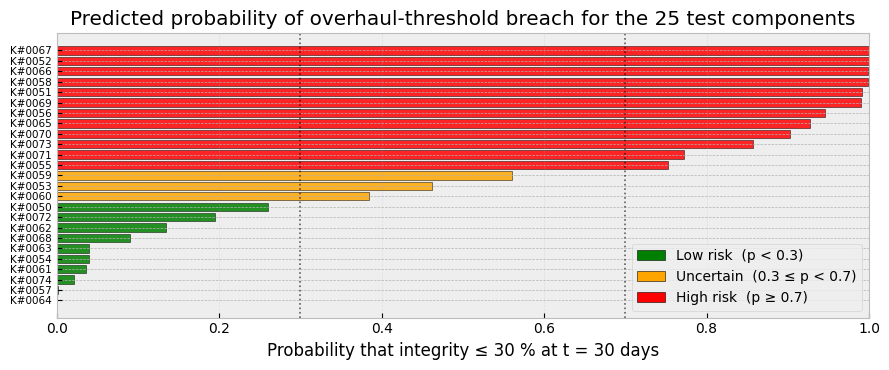

In [46]:
pred_sorted = predictions_df.sort_values("probability").reset_index(drop=True)
probs  = pred_sorted["probability"].values
ids    = pred_sorted["ID"].values

bar_colours = ["green" if p < 0.3 else "orange" if p < 0.7 else "red"
               for p in probs]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(np.arange(len(probs)), probs, color=bar_colours,
        alpha=0.85, edgecolor="black", linewidth=0.4)
ax.set_yticks(np.arange(len(probs)))
ax.set_yticklabels(ids, fontsize=7.5)
ax.set_xlabel("Probability that integrity ≤ 30 % at t = 30 days")
ax.set_xlim(0, 1)
ax.axvline(0.3, color="black", linestyle=":", lw=1.2, alpha=0.6)
ax.axvline(0.7, color="black", linestyle=":", lw=1.2, alpha=0.6)
ax.set_title("Predicted probability of overhaul-threshold breach for the 25 test components")
ax.grid(True, alpha=0.25, axis="x")

ax.legend(handles=[
    Patch(facecolor="green", edgecolor="black", lw=0.4, label="Low risk  (p < 0.3)"),
    Patch(facecolor="orange", edgecolor="black", lw=0.4, label="Uncertain  (0.3 ≤ p < 0.7)"),
    Patch(facecolor="red", edgecolor="black", lw=0.4, label="High risk  (p ≥ 0.7)"),],
    loc="lower right")

plt.tight_layout()
plt.show()